<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/03_portfolio_dependence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 - S&P 500 and Apple: how they move together

Before the portfolio backtest (04): correlation over time, DCC correlation, joint crashes. Apple prices are adjusted for its 4 splits.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from risk import *

prices = pd.concat({"spx": load_close("../black-scholes-sp500/data/sp500.csv"),
                    "aapl": load_close("data/aapl.csv")}, axis=1).dropna()
rets = np.log(prices).diff().dropna()
simple = np.exp(rets) - 1
w = np.array([0.5, 0.5])
port = np.log1p(simple @ w)   # 50/50, rebalanced every day
len(rets), rets.index[0].date(), rets.index[-1].date()

(6761, datetime.date(2000, 1, 4), datetime.date(2026, 11, 19))

In [3]:
print("annual vol  spx", round(rets.spx.std() * np.sqrt(252), 3), " aapl", round(rets.aapl.std() * np.sqrt(252), 3),
      " 50/50", round(port.std() * np.sqrt(252), 3))
print("correlation", round(rets.corr().iloc[0, 1], 3))
for y0, y1 in [(2000, 2004), (2005, 2009), (2010, 2014), (2015, 2019), (2020, 2026)]:
    print(f"  {y0}-{y1}  {rets.loc[str(y0):str(y1)].corr().iloc[0, 1]:.2f}")
# apple twice as volatile as the index. 50/50 vol (0.26) below the average (0.29) = diversification

annual vol  spx 0.192  aapl 0.394  50/50 0.26
correlation 0.558
  2000-2004  0.46
  2005-2009  0.58
  2010-2014  0.54
  2015-2019  0.67
  2020-2026  0.75


DCC(1,1), Engle (2002), on the GARCH residuals of each asset: $Q_t = (1-a-b)\bar Q + a\,z_{t-1}z_{t-1}^\top + b\,Q_{t-1}$, correlation $R_t$ = $Q_t$ rescaled to 1 on the diagonal.

dcc a 0.025  b 0.969


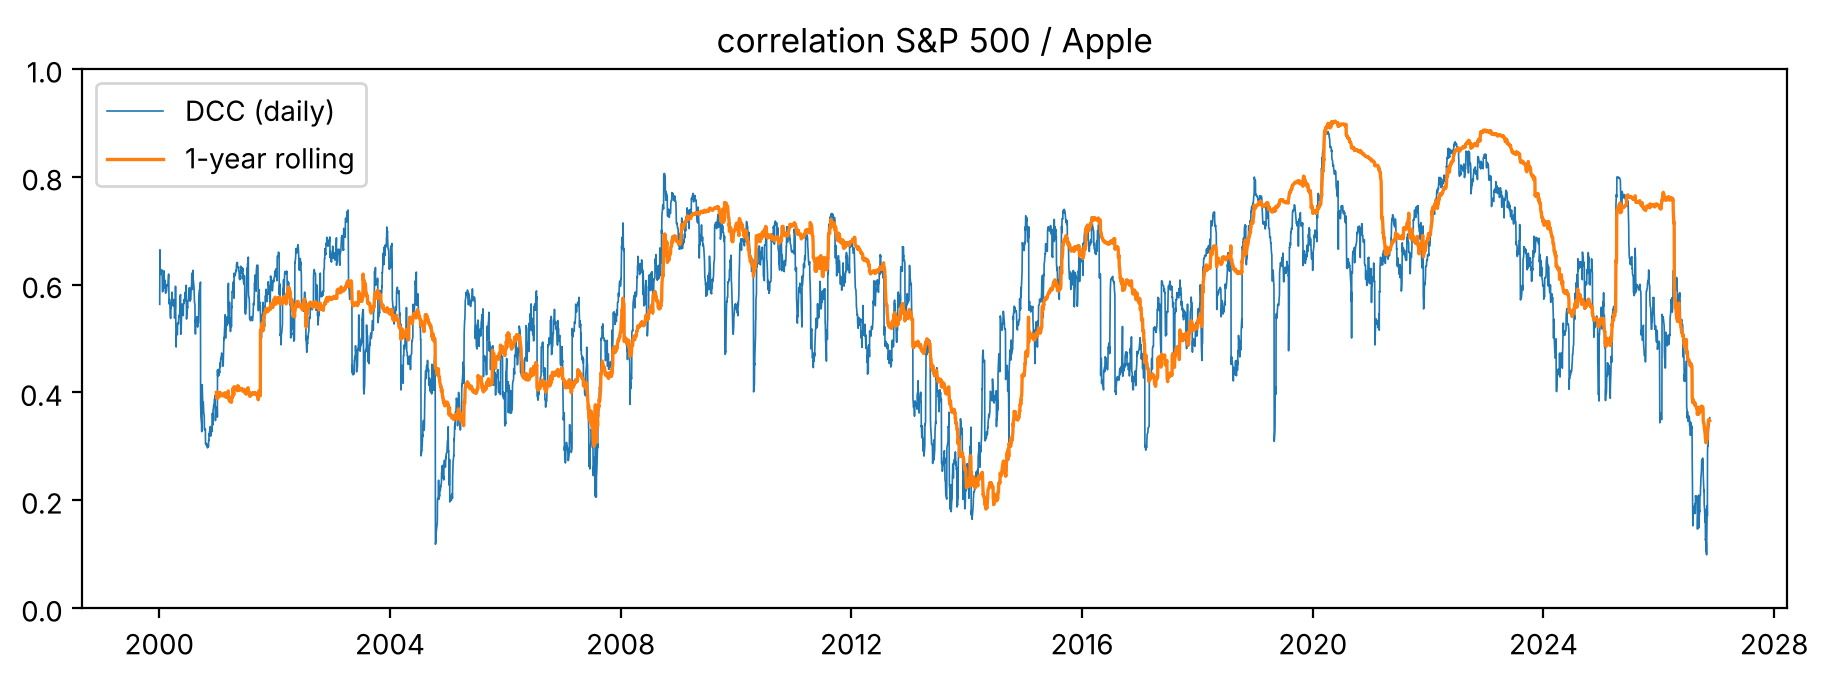

In [4]:
X = rets.values - rets.values.mean(axis=0)
Z = np.column_stack([X[:, i] / np.sqrt(garch_filter(X[:, i], *garch_fit(rets.values[:, i]))[:-1]) for i in range(2)])
a_dcc, b_dcc = dcc_fit(Z)
dcc_corr = pd.Series(dcc_filter(Z, a_dcc, b_dcc)[:-1, 0, 1], index=rets.index)
roll_corr = rets.spx.rolling(250).corr(rets.aapl)
print("dcc a", round(a_dcc, 3), " b", round(b_dcc, 3))

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(dcc_corr, lw=0.6, label="DCC (daily)")
ax.plot(roll_corr, lw=1.2, label="1-year rolling")
ax.set_ylim(0, 1); ax.set_title("correlation S&P 500 / Apple"); ax.legend()
plt.show()
# not a trend: 0.2 in 2014, 0.9 in may 2020, high until 2023, back to ~0.35 at the end of 2026
# jumps in crises (2008: ~0.4 -> 0.7). part of the rise is mechanical: apple is now a big piece of the index
# dcc moves within days, the rolling one within months

In [5]:
u = rets.rank(pct=True)
rho = np.sin(np.pi / 2 * stats.kendalltau(rets.spx, rets.aapl)[0])
gauss = stats.multivariate_normal([0, 0], [[1, rho], [rho, 1]])
rho_t, nu = t_copula_fit(rets.values)
tcop = stats.multivariate_t(shape=[[1, rho_t], [rho_t, 1]], df=nu)
print("t copula: rho", round(rho_t, 3), " nu", round(nu, 1))
for q in [0.05, 0.01]:
    data = ((u.spx <= q) & (u.aapl <= q)).mean() / q
    up = ((u.spx >= 1 - q) & (u.aapl >= 1 - q)).mean() / q
    print(f"worst {q:.0%} days, both down: data {data:.3f}  gaussian {gauss.cdf([stats.norm.ppf(q)] * 2) / q:.3f}  "
          f"t {tcop.cdf([stats.t.ppf(q, nu)] * 2) / q:.3f}   (both up: {up:.3f})")
print("tail dependence: t", round(2 * stats.t.cdf(-np.sqrt((nu + 1) * (1 - rho_t) / (1 + rho_t)), nu + 1), 3), " gaussian 0")
# worst 1% days: they fall together 28% of the time. gaussian says 20% (too few), t copula 35% (a bit too many)
# same thing on the up side, so it is not only crashes
# nu ~ 4.5 -> far from gaussian. at the extreme the t copula keeps ~30% of joint crashes, the gaussian 0

t copula: rho 0.621  nu 4.5
worst 5% days, both down: data 0.376  gaussian 0.326  t 0.408   (both up: 0.340)
worst 1% days, both down: data 0.281  gaussian 0.202  t 0.350   (both up: 0.296)
tail dependence: t 0.305  gaussian 0
